## Let's look at the data

#### Imports

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from Utils.Utils import (load_covertype_data,split_data,PreprocessingConfig,AspectTransformer
,RareSoilFilter,build_preprocessor)

In [2]:
X, y = load_covertype_data()

Loading local dataset from 'C:\Users\Solal\Documents\Cours\centrale_supelec\dossier 3A_cs\Control Engineering\DAML\DAML-Forest-Cover-Type-Classification\DATA\raw'
Filtering the dataset based on active features...


How big is the dataset ?

In [3]:
print('Data Dimension:')
print('Number of Records:', X.shape[0])
print('Number of Features:', X.shape[1])

Data Dimension:
Number of Records: 581012
Number of Features: 54


What does the dataset look like ?

In [4]:
X.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,0
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,0
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,0
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,0
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,0


In [5]:
y.head()

,Cover_Type
0,5
1,5
2,2
3,2
4,5


In [6]:
print('Feature Names')
print(X.columns)

Feature Names
Index(['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology',
       'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways',
       'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm',
       'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area1', 'Soil_Type1',
       'Soil_Type2', 'Soil_Type3', 'Soil_Type4', 'Soil_Type5', 'Soil_Type6',
       'Soil_Type7', 'Soil_Type8', 'Soil_Type9', 'Soil_Type10', 'Soil_Type11',
       'Soil_Type12', 'Soil_Type13', 'Soil_Type14', 'Soil_Type15',
       'Soil_Type16', 'Soil_Type17', 'Soil_Type18', 'Soil_Type19',
       'Soil_Type20', 'Soil_Type21', 'Soil_Type22', 'Soil_Type23',
       'Soil_Type24', 'Soil_Type25', 'Soil_Type26', 'Soil_Type27',
       'Soil_Type28', 'Soil_Type29', 'Soil_Type30', 'Soil_Type31',
       'Soil_Type32', 'Soil_Type33', 'Soil_Type34', 'Soil_Type35',
       'Soil_Type36', 'Soil_Type37', 'Soil_Type38', 'Soil_Type39',
       'Soil_Type40', 'Wilderness_Area2', 'Wilderness_Area3',
       'Wi

### Do we have Null values ?

In [34]:
missing_values = pd.DataFrame({
    "NaN": X.isna().sum(),
    "+Inf": np.isposinf(X).sum(),
    "-Inf": np.isneginf(X).sum()
})

missing_values["Total"] = missing_values.sum(axis=1)

invalid_features = missing_values[missing_values["Total"] > 0]

if invalid_features.empty:
    print("No missing or infinite values found.")
else:
    display(invalid_features)

No missing or infinite values found.


#### No we don't !!

### Does the data look clean ?

In [8]:
X.describe()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4
count,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,...,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000
mean,2959.365301,155.656807,14.103704,269.428217,46.418855,2350.146611,212.146049,223.318716,142.528263,1980.291226,...,0.002773,0.003255,0.000205,0.000513,0.026803,0.023762,0.015060,0.051434,0.436074,0.063627
std,279.984734,111.913721,7.488242,212.549356,58.295232,1559.254870,26.769889,19.768697,38.274529,1324.195210,...,0.052584,0.056957,0.014310,0.022641,0.161508,0.152307,0.121791,0.220882,0.495897,0.244087
min,1859.000000,0.000000,0.000000,0.000000,-173.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2809.000000,58.000000,9.000000,108.000000,7.000000,1106.000000,198.000000,213.000000,119.000000,1024.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2996.000000,127.000000,13.000000,218.000000,30.000000,1997.000000,218.000000,226.000000,143.000000,1710.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,3163.000000,260.000000,18.000000,384.000000,69.000000,3328.000000,231.000000,237.000000,168.000000,2550.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,3858.000000,360.000000,66.000000,1397.000000,601.000000,7117.000000,254.000000,254.000000,254.000000,7173.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Vertical_Distance_To_Hydrology : Min = -173. <span style="color: red;">Does that make sense ?</span>. It makes sense as a negative distance means its lower than the water, its a signed distance here. 

In [31]:
wilderness_cols = [
    c for c in X.columns if c.startswith("Wilderness_Area")
]
soil_cols = [
    c for c in X.columns if c.startswith("Soil_Type")
]

print("Invalid Wilderness encoding:",
      (X[wilderness_cols].sum(axis=1) != 1).sum())

print("Invalid Soil encoding:",
      (X[soil_cols].sum(axis=1) != 1).sum())

print("Duplicated feature rows:", X.duplicated().sum())

print("Duplicated observations:",
      pd.concat([X, y], axis=1).duplicated().sum())

Invalid Wilderness encoding: 0
Invalid Soil encoding: 0
Duplicated feature rows: 0
Duplicated observations: 0


### How are our labels distributed ?

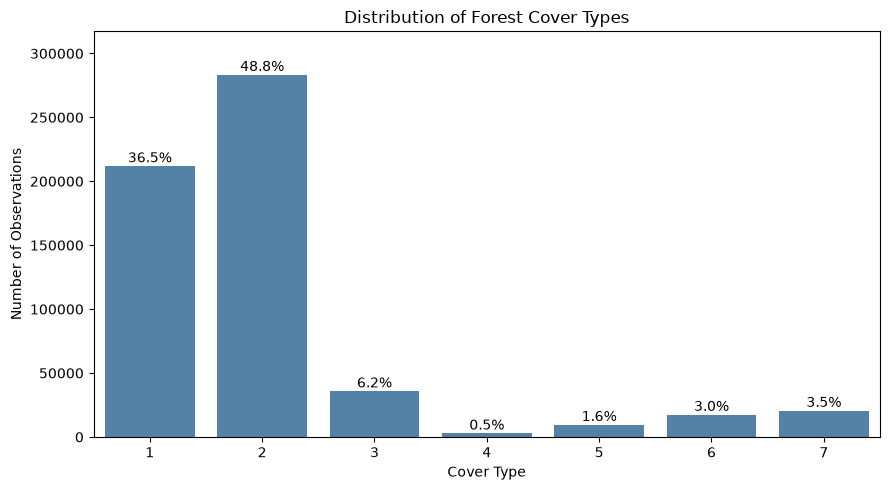

In [9]:
class_counts = y["Cover_Type"].value_counts().sort_index()
class_proportions = class_counts / len(y) * 100

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    color="steelblue",
    ax=ax
)

for i, (count, proportion) in enumerate(
    zip(class_counts.values, class_proportions.values)
):
    ax.text(
        i,
        count + 3000,
        f"{proportion:.1f}%",
        ha="center"
    )

ax.set_title("Distribution of Forest Cover Types")
ax.set_xlabel("Cover Type")
ax.set_ylabel("Number of Observations")
ax.set_ylim(0, class_counts.max() * 1.12)

plt.tight_layout()
plt.show()

The dataset is highly imbalanced. Cover types 1 and 2 account for approximately 85% of all observations, while cover type 4 represents less than 0.5%.
We need some good metrics because only acccuracy would already be 48 percent with a trivial classifier always answering 2. 

## Insights

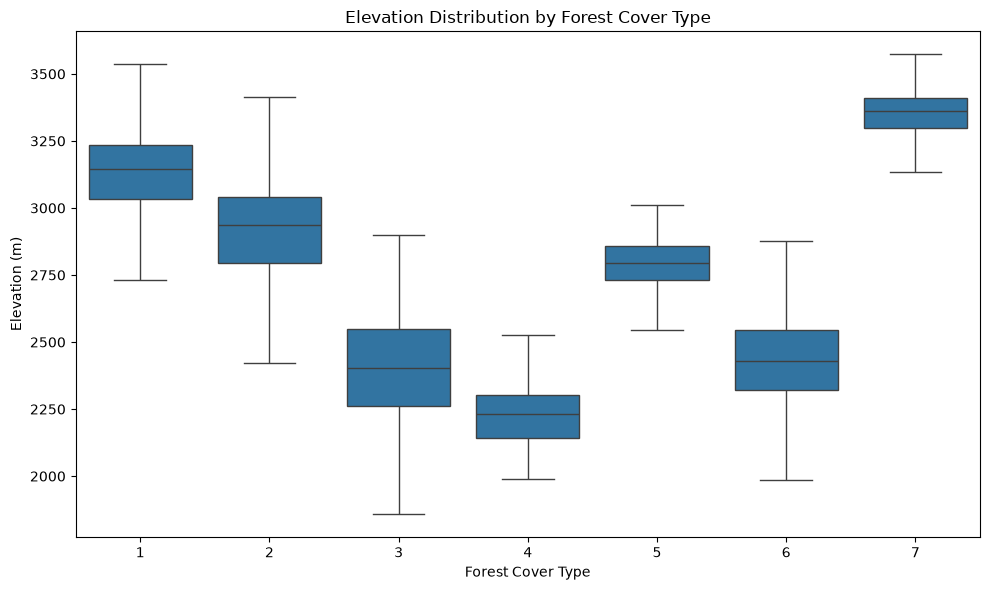

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    x=y["Cover_Type"],
    y=X["Elevation"],
    showfliers=False,
    ax=ax
)

ax.set_title("Elevation Distribution by Forest Cover Type")
ax.set_xlabel("Forest Cover Type")
ax.set_ylabel("Elevation (m)")

plt.tight_layout()
plt.show()

**Elevation analysis**

Elevation appears to be a highly discriminative feature for forest cover type classification. Different classes exhibit distinct altitude ranges, with cover types 1 and 7 predominantly found at high elevations, while types 3, 4 and 6 are associated with lower elevations.

However, significant overlaps remain, particularly between classes 1 and 2, and between classes 3 and 6. Therefore, elevation alone is unlikely to be sufficient for accurate classification of all seven classes.

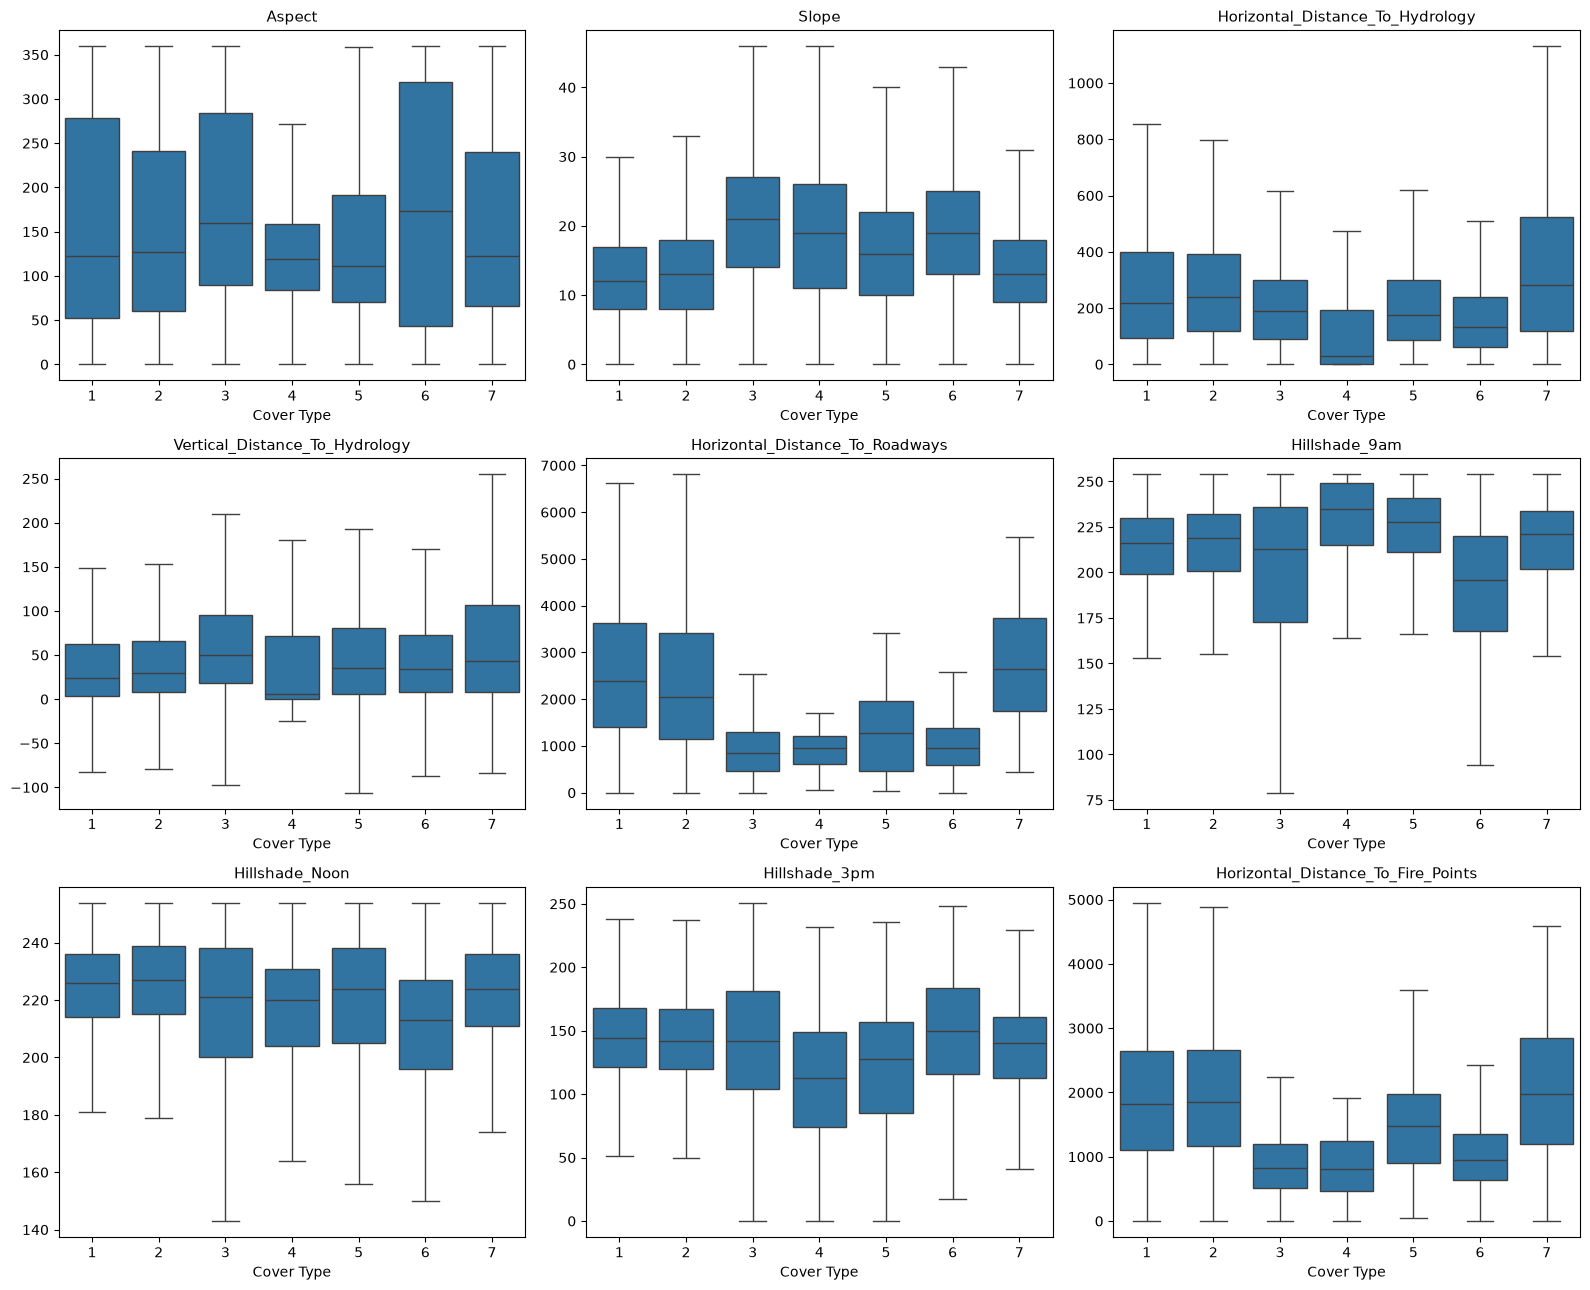

In [11]:
numeric_features = X.columns[:10]

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.flatten()

for ax, feature in zip(axes, numeric_features[1:]):
    sns.boxplot(
        x=y["Cover_Type"],
        y=X[feature],
        showfliers=False,
        ax=ax
    )

    ax.set_title(feature, fontsize=11)
    ax.set_xlabel("Cover Type")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

**Numerical feature distributions**

Several numerical features exhibit distinct distributions across forest cover types. Elevation is particularly discriminative, while horizontal distances to roadways and fire ignition points, as well as slope, also show substantial differences between groups of classes.

Hydrological and hillshade features generally exhibit greater overlap, although some specific classes can still be distinguished.

Aspect requires special consideration because it represents a circular variable: orientations near 0° and 360° are physically close despite their numerical difference.

Overall, these observations suggest that several features contain complementary information and that interactions between variables may be important for classification.

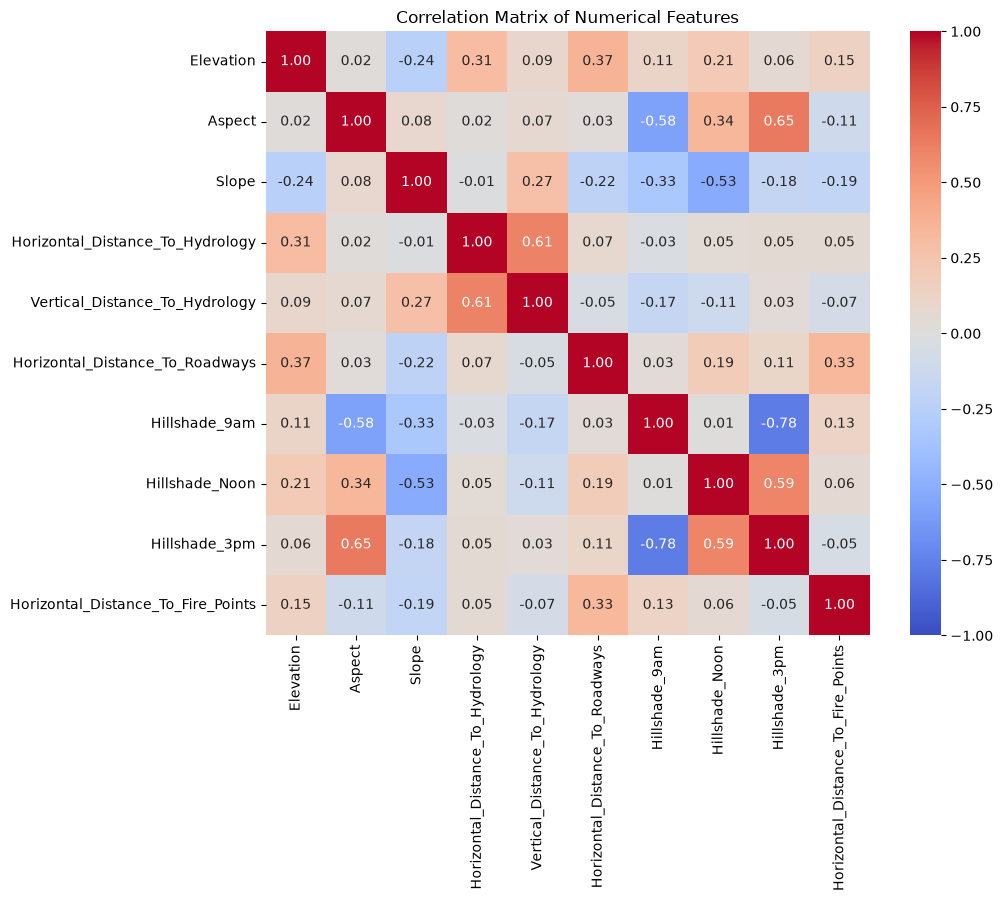

In [12]:
numeric_features = X.columns[:10]

correlation_matrix = X[numeric_features].corr()

plt.figure(figsize=(11, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

**Correlation analysis**

The correlation matrix reveals several significant linear relationships, particularly among the hillshade variables and terrain orientation. The strongest correlation is observed between Hillshade_9am and Hillshade_3pm (-0.78), suggesting partial redundancy in the solar exposure information.

The horizontal and vertical distances to hydrology are also correlated (0.61), whereas distances to roadways and fire ignition points show only moderate correlation (0.33), despite exhibiting similar class-dependent distributions.

Elevation, previously identified as a potentially discriminative feature, is only moderately correlated with the other numerical variables.

These results motivate investigating PCA as a dimensionality reduction technique. However, the relatively weak correlations among many features suggest that substantial dimensionality reduction may result in information loss.

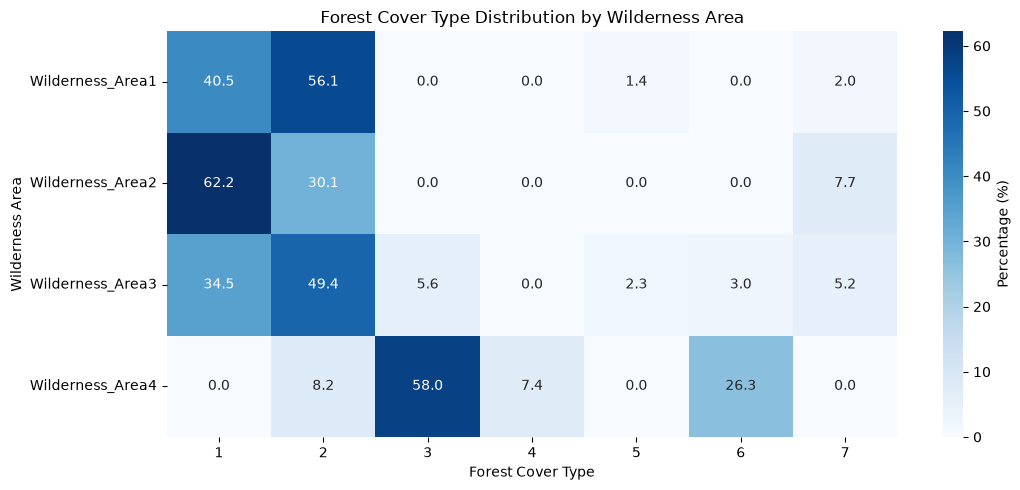

In [13]:
wilderness_cols = [
    col for col in X.columns
    if col.startswith("Wilderness_Area")
]

# Recover the categorical wilderness area from one-hot encoding
wilderness_area = X[wilderness_cols].idxmax(axis=1)

# Contingency table, normalized by wilderness area
distribution = pd.crosstab(
    wilderness_area,
    y["Cover_Type"],
    normalize="index"
)

plt.figure(figsize=(11, 5))

sns.heatmap(
    distribution * 100,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    cbar_kws={"label": "Percentage (%)"}
)

plt.title("Forest Cover Type Distribution by Wilderness Area")
plt.xlabel("Forest Cover Type")
plt.ylabel("Wilderness Area")

plt.tight_layout()
plt.show()

**Wilderness Area analysis**

Forest cover type distributions vary substantially across wilderness areas. Areas 1 and 2 are dominated by cover types 1 and 2, while Area 3 exhibits greater diversity.

Area 4 has a markedly different distribution, dominated by cover types 3 and 6. Notably, cover type 4 is observed exclusively in this area.

These results suggest that wilderness area contains valuable information for classification. However, the strong association between geographical location and cover type also raises questions about the ability of classifiers to generalize to unseen geographical areas.

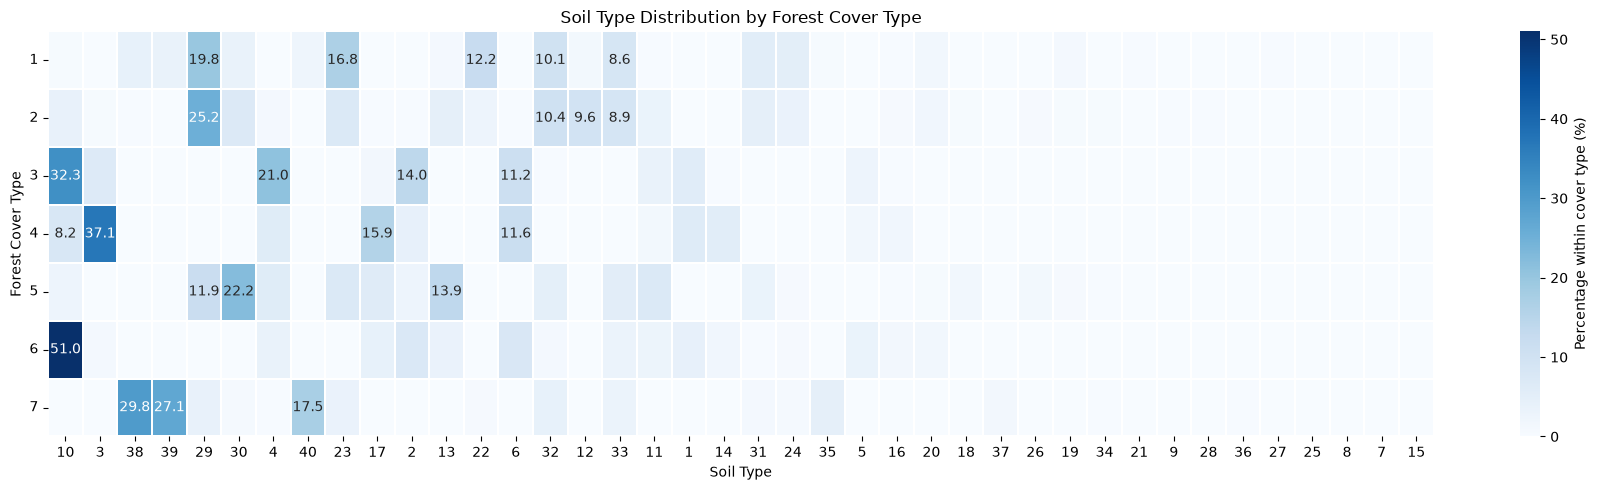

In [14]:
soil_cols = [col for col in X.columns if col.startswith("Soil_Type")]

# Recover soil type from one-hot encoding
soil_type = X[soil_cols].idxmax(axis=1)

# Distribution of soil types within each forest cover class
soil_distribution = pd.crosstab(
    y["Cover_Type"],
    soil_type,
    normalize="index"
) * 100

# Reorder soil types by their maximum percentage across classes
soil_order = soil_distribution.max(axis=0).sort_values(ascending=False).index
soil_distribution = soil_distribution[soil_order]

# Shorter labels: keep only the soil number
short_labels = [col.replace("Soil_Type", "") for col in soil_distribution.columns]

# Annotate only sufficiently large values
annot_data = soil_distribution.copy().round(1).astype(str)
annot_data = annot_data.where(soil_distribution >= 8, "")

plt.figure(figsize=(18, 5))

sns.heatmap(
    soil_distribution,
    cmap="Blues",
    annot=annot_data,
    fmt="",
    linewidths=0.3,
    cbar_kws={"label": "Percentage within cover type (%)"}
)

plt.title("Soil Type Distribution by Forest Cover Type")
plt.xlabel("Soil Type")
plt.ylabel("Forest Cover Type")
plt.xticks(
    ticks=np.arange(len(short_labels)) + 0.5,
    labels=short_labels,
    rotation=0
)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [15]:
# Overall frequency of each soil type
soil_counts = X[soil_cols].sum()
soil_frequency = 100 * soil_counts / len(X)

# Class distribution conditional on each soil type
soil_class_distribution = pd.crosstab(
    soil_type,
    y["Cover_Type"],
    normalize="index"
)

soil_summary = pd.DataFrame({
    "Count": soil_counts,
    "Frequency (%)": soil_frequency,
    "Dominant Class": soil_class_distribution.idxmax(axis=1),
    "Dominant Class (%)": 100 * soil_class_distribution.max(axis=1)
})

soil_summary = soil_summary.sort_values("Frequency (%)")

display(soil_summary.round(2))

,Count,Frequency (%),Dominant Class,Dominant Class (%)
Soil_Type15,3,0.00,6,100.00
Soil_Type7,105,0.02,2,100.00
Soil_Type36,119,0.02,7,52.94
Soil_Type8,179,0.03,2,75.98
Soil_Type37,298,0.05,7,100.00
Soil_Type25,474,0.08,2,73.63
Soil_Type14,599,0.10,6,54.76
Soil_Type21,838,0.14,1,95.94
Soil_Type28,946,0.16,2,94.19
Soil_Type27,1086,0.19,1,55.62


**Rare soil types and potential feature selection**

Several soil types are extremely rare, with six categories representing less than 0.1% of the dataset individually.

However, rarity does not necessarily imply irrelevance. Some rare soil types are strongly associated with specific forest cover classes, such as Soil_Type37, which appears exclusively in cover type 7 in the observed dataset.

Furthermore, class imbalance must be considered when interpreting conditional distributions: the most frequent cover type for a given soil is not necessarily the cover type for which that soil is most characteristic.

**The relevance of extremely rare soil types remains uncertain.** Their low sample counts may make the observed class associations statistically unreliable, particularly for categories represented by only a handful of observations. Further investigation is therefore needed to determine whether these variables should be retained or removed. This decision should be based on their predictive contribution, assessed through experiments with and without rare soil types, rather than on frequency alone.

## Data Processing

### Linear vs. Circular Representation of Aspect

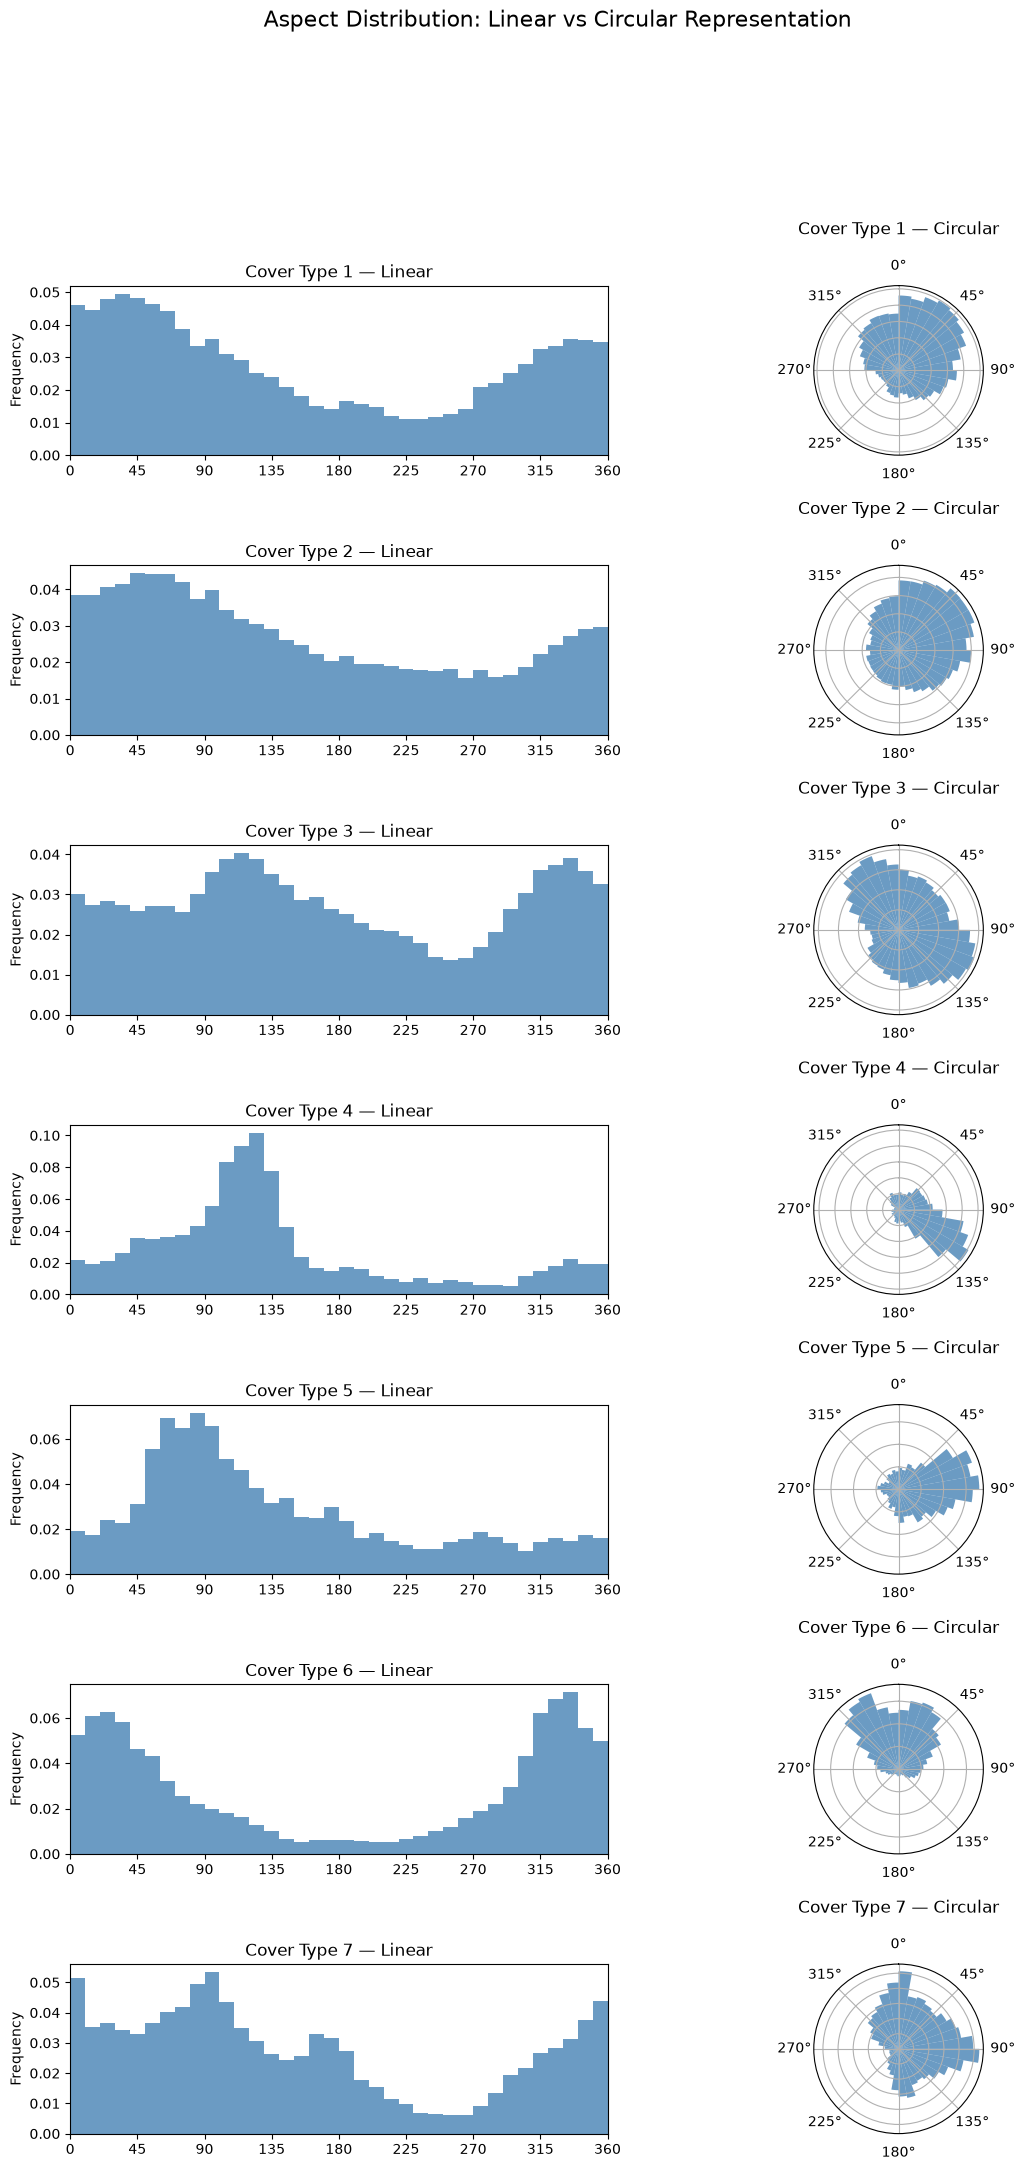

In [16]:
bins = np.linspace(0, 360, 37)
centers_deg = (bins[:-1] + bins[1:]) / 2
centers_rad = np.deg2rad(centers_deg)
width_rad = np.deg2rad(10)

classes = sorted(y["Cover_Type"].unique())

fig = plt.figure(figsize=(13, 24))
gs = fig.add_gridspec(
    nrows=7, ncols=2,
    width_ratios=[1.5, 1],
    hspace=0.65,
    wspace=0.25
)

for i, cover_type in enumerate(classes):
    angles = X.loc[
        y["Cover_Type"] == cover_type, "Aspect"
    ].to_numpy()

    counts, _ = np.histogram(angles, bins=bins)
    frequencies = counts / counts.sum()

    # Linear representation
    ax_linear = fig.add_subplot(gs[i, 0])

    ax_linear.bar(
        centers_deg,
        frequencies,
        width=10,
        color="steelblue",
        alpha=0.8
    )

    ax_linear.set_xlim(0, 360)
    ax_linear.set_xticks(np.arange(0, 361, 45))
    ax_linear.set_ylabel("Frequency")
    ax_linear.set_title(f"Cover Type {cover_type} — Linear")

    # Circular representation
    ax_polar = fig.add_subplot(gs[i, 1], projection="polar")

    ax_polar.bar(
        centers_rad,
        frequencies,
        width=width_rad,
        color="steelblue",
        alpha=0.8
    )

    ax_polar.set_theta_zero_location("N")
    ax_polar.set_theta_direction(-1)
    ax_polar.set_title(f"Cover Type {cover_type} — Circular", pad=18)
    ax_polar.set_yticklabels([])

plt.suptitle(
    "Aspect Distribution: Linear vs Circular Representation",
    fontsize=16,
    y=0.995
)

plt.show()

The comparison highlights the limitations of representing `Aspect` as a linear variable. Since terrain orientation is periodic, angles close to 0° and 360° represent similar directions, despite being numerically far apart.

This issue is particularly visible for **Cover Type 6**, whose distribution exhibits two apparent peaks near 0° and 360° in the linear histogram. The circular representation reveals that these peaks actually belong to the same continuous concentration of orientations around North.

Similar effects can be observed for other cover types, although their angular distributions differ substantially.

To account for this periodicity, we propose replacing the original `Aspect` feature with two components:

$$\text{Aspect}_{\cos}=\cos(\theta), \qquad
\text{Aspect}_{\sin}=\sin(\theta)$$

where $\theta$ is expressed in radians.

This representation eliminates the artificial discontinuity at 0°/360° and preserves angular proximity. **Its impact on classification performance will be evaluated by comparing models trained with and without this transformation.**

### Train / Validation / Test Split

Before applying data-dependent preprocessing, we split the dataset into three subsets:

- **Training (70%)**: used to fit model parameters and preprocessing transformations.
- **Validation (15%)**: used to compare preprocessing configurations, classifiers and hyperparameters.
- **Test (15%)**: kept separate for the final evaluation.

We compare two splitting strategies:

- **Random splitting**, where observations are assigned randomly.
- **Stratified splitting**, which preserves approximately the original class proportions in each subset.

Since the dataset is large, both methods are expected to produce similar class distributions. However, stratification provides more consistent representation of minority classes.

In [17]:
splits = {
    method: split_data(
        X, y,
        method=method,
        train_size=0.70,
        val_size=0.15,
        test_size=0.15,
        random_state=42
    )
    for method in ["random", "stratified"]
}

for method, (X_tr, X_va, X_te, _, _, _) in splits.items():
    print(f"{method.capitalize()} split:")
    print(f"  Train:      {X_tr.shape}")
    print(f"  Validation: {X_va.shape}")
    print(f"  Test:       {X_te.shape}")

Random split:
  Train:      (406708, 54)
  Validation: (87152, 54)
  Test:       (87152, 54)
Stratified split:
  Train:      (406708, 54)
  Validation: (87152, 54)
  Test:       (87152, 54)


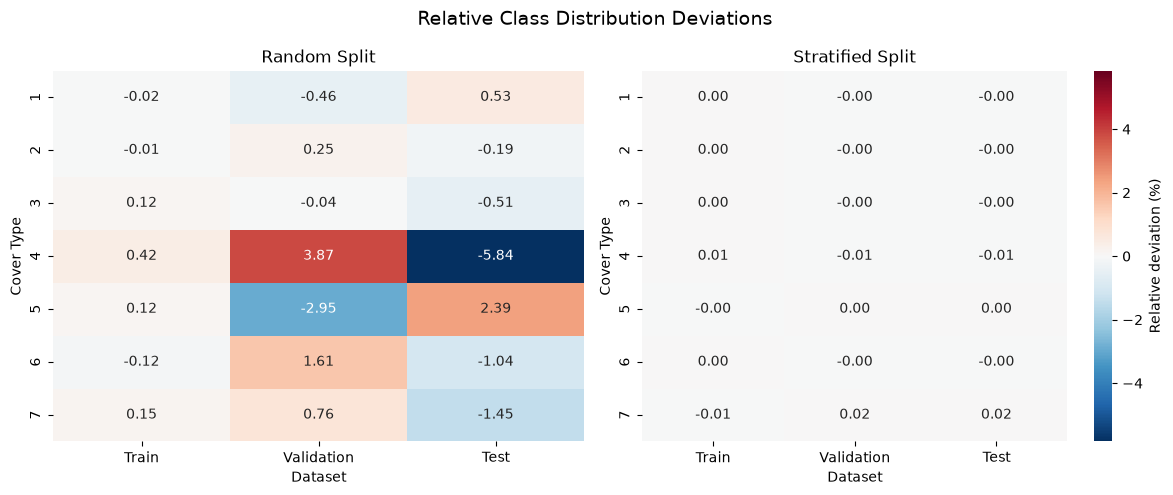

In [18]:
original_proportions = (
    y["Cover_Type"].value_counts(normalize=True).sort_index()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

deviations_by_method = {}

for method, split in splits.items():
    _, _, _, y_tr, y_va, y_te = split

    proportions = pd.DataFrame({
        "Train": y_tr.squeeze().value_counts(normalize=True),
        "Validation": y_va.squeeze().value_counts(normalize=True),
        "Test": y_te.squeeze().value_counts(normalize=True)
    }).reindex(original_proportions.index, fill_value=0)

    # Relative deviation from the original class frequency (%)
    deviations_by_method[method] = (
        proportions.div(original_proportions, axis=0) - 1
    ) * 100

max_deviation = max(
    deviations.abs().to_numpy().max()
    for deviations in deviations_by_method.values()
)

for ax, method in zip(axes, ["random", "stratified"]):
    sns.heatmap(
        deviations_by_method[method],
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        center=0,
        vmin=-max_deviation,
        vmax=max_deviation,
        cbar=(method == "stratified"),
        cbar_kws={"label": "Relative deviation (%)"},
        ax=ax
    )

    ax.set_title(f"{method.capitalize()} Split")
    ax.set_xlabel("Dataset")
    ax.set_ylabel("Cover Type")

plt.suptitle(
    "Relative Class Distribution Deviations",
    fontsize=14
)
plt.tight_layout()
plt.show()

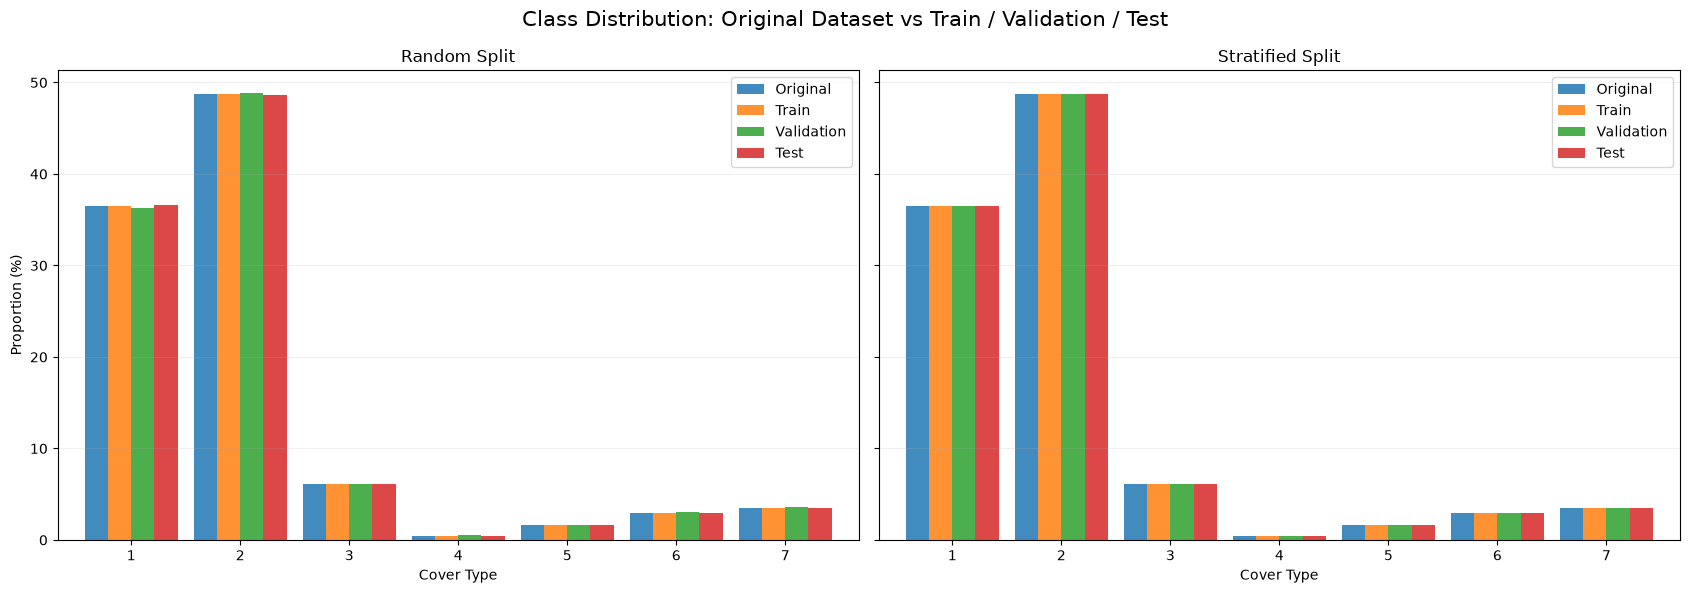

In [20]:
original_proportions = (
    y["Cover_Type"].value_counts(normalize=True).sort_index() * 100
)

fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharey=True)

for ax, (method, split) in zip(axes, splits.items()):
    _, _, _, y_tr, y_va, y_te = split

    proportions = pd.DataFrame({
        "Original": original_proportions,
        "Train": y_tr.squeeze().value_counts(normalize=True) * 100,
        "Validation": y_va.squeeze().value_counts(normalize=True) * 100,
        "Test": y_te.squeeze().value_counts(normalize=True) * 100,
    }).sort_index()

    proportions.plot.bar(
        ax=ax,
        width=0.85,
        alpha=0.85
    )

    ax.set_title(f"{method.capitalize()} Split")
    ax.set_xlabel("Cover Type")
    ax.set_ylabel("Proportion (%)")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.2)
    ax.legend()

plt.suptitle(
    "Class Distribution: Original Dataset vs Train / Validation / Test",
    fontsize=15
)

plt.tight_layout()
plt.show()

### Random vs. Stratified Splitting

Both splitting strategies produce class distributions close to the original dataset, as expected given its large size.

However, random splitting introduces small deviations, particularly in the validation and test sets. Stratified splitting preserves the class proportions almost exactly, resulting in deviations that are nearly invisible at the scale of the figure.

Stratification does not address class imbalance, but it ensures a more consistent representation of all seven classes across the training, validation and test sets.

We therefore adopt **stratified splitting (70% / 15% / 15%)** for the subsequent experiments, with a fixed random seed to ensure reproducibility.

In [21]:
X_train, X_val, X_test, y_train, y_val, y_test = splits["stratified"]

## PCA

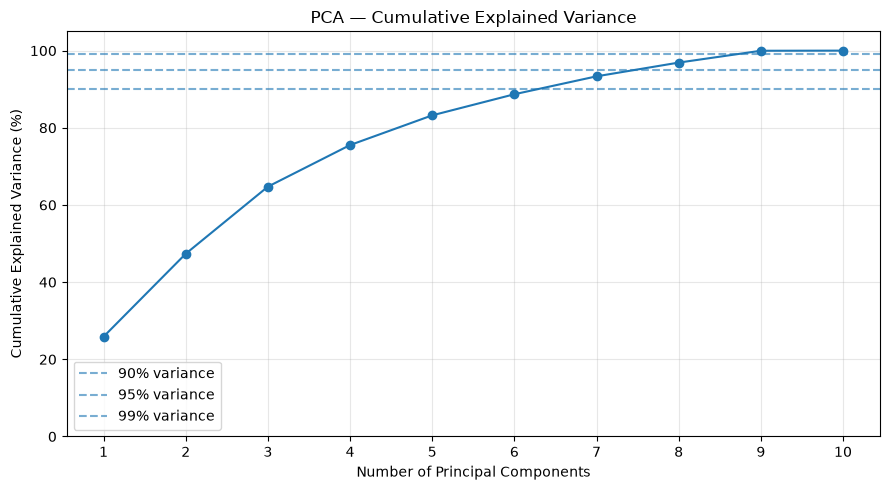

90% variance: 7 components
95% variance: 8 components
99% variance: 9 components


In [22]:
numeric_features = X.columns[:10]

config = PreprocessingConfig(
    pca="numeric",
    pca_components=10,
    cyclic_aspect=False,
)

preprocessor = build_preprocessor(config)
preprocessor.fit(X_train)

pca = preprocessor.named_steps["features"] \
    .named_transformers_["numeric"] \
    .named_steps["pca"]

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="o"
)

for threshold in [90, 95, 99]:
    ax.axhline(
        threshold,
        linestyle="--",
        alpha=0.6,
        label=f"{threshold}% variance"
    )

ax.set_xlabel("Number of Principal Components")
ax.set_ylabel("Cumulative Explained Variance (%)")
ax.set_title("PCA — Cumulative Explained Variance")
ax.set_xticks(range(1, 11))
ax.set_ylim(0, 105)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

for threshold in [0.90, 0.95, 0.99]:
    n_components = np.searchsorted(
        cumulative_variance, threshold
    ) + 1

    print(f"{threshold:.0%} variance: {n_components} components")

### PCA — Explained Variance Analysis

PCA was applied to the 10 standardized numerical features using the training dataset.

The first three principal components explain approximately 65% of the total variance. Retaining 7, 8 and 9 components preserves approximately 90%, 95% and 99% of the variance, respectively.

These results indicate moderate redundancy among the numerical features. However, retaining 95% of the variance only reduces the number of numerical features from 10 to 8. Since the 44 binary features are preserved, the overall dimensionality decreases from 54 to 52.

Therefore, the expected computational benefit of numerical PCA is limited. Nevertheless, its impact on classification performance remains worth investigating, since explained variance does not necessarily reflect discriminative information.

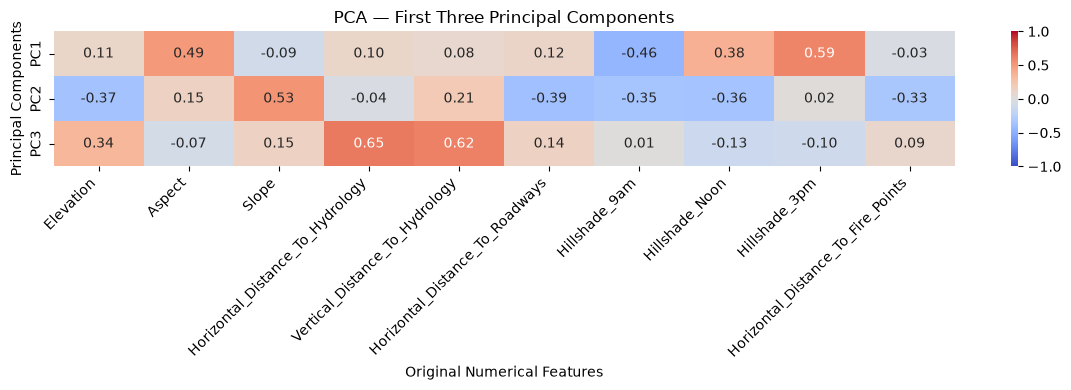

In [23]:
components = pd.DataFrame(
    pca.components_[:3],
    columns=numeric_features,
    index=["PC1", "PC2", "PC3"]
)

plt.figure(figsize=(12, 4))

sns.heatmap(
    components,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("PCA — First Three Principal Components")
plt.xlabel("Original Numerical Features")
plt.ylabel("Principal Components")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Interpretation of the Principal Components

The first three principal components reveal several meaningful combinations of environmental variables.

- **PC1** is primarily associated with terrain orientation and solar exposure, combining Aspect, Hillshade_9am and Hillshade_3pm. This is consistent with the correlations previously identified between these features.
- **PC2** combines slope, elevation, distance to roadways and midday hillshade, reflecting several aspects of terrain topography.
- **PC3** is dominated by the horizontal and vertical distances to hydrology, capturing their shared variability.

These results show that PCA combines correlated environmental features into new, orthogonal dimensions. However, these components maximize explained variance rather than class separability, so their usefulness for classification remains to be evaluated.

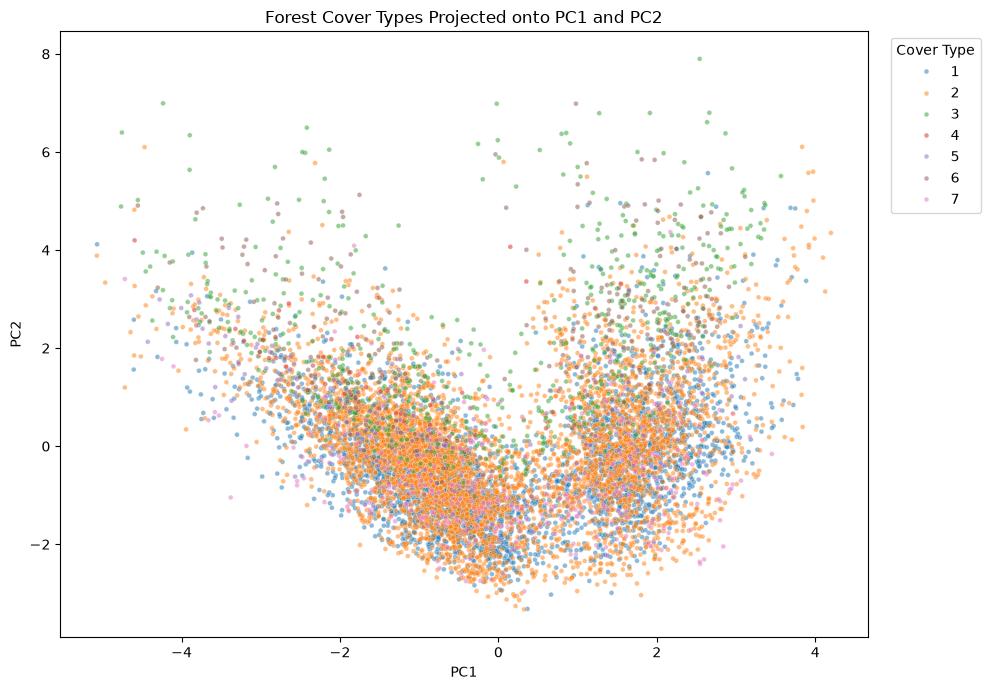

In [25]:
# Transform training data with the already fitted preprocessor
X_train_pca = preprocessor.transform(X_train)

# The first columns correspond to numerical principal components
pc1 = X_train_pca[:, 0]
pc2 = X_train_pca[:, 1]

# Stratified sample for visualization
rng = np.random.default_rng(42)

sample_idx = np.concatenate([
    rng.choice(
        np.flatnonzero(y_train.squeeze().to_numpy() == class_id),
        size=round(10000 * np.mean(y_train.squeeze().to_numpy() == class_id)),
        replace=False
    )
    for class_id in sorted(y_train.squeeze().unique())
])

fig, ax = plt.subplots(figsize=(10, 7))

sns.scatterplot(
    x=pc1[sample_idx],
    y=pc2[sample_idx],
    hue=y_train.squeeze().iloc[sample_idx],
    palette="tab10",
    s=12,
    alpha=0.5,
    ax=ax
)

ax.set_title("Forest Cover Types Projected onto PC1 and PC2")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(title="Cover Type", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

### PCA — Projection onto the First Two Principal Components

The projection of the numerical features onto PC1 and PC2 reveals a structured, approximately U-shaped distribution, suggesting that the principal components capture non-trivial relationships between the environmental variables.

However, the seven forest cover classes overlap substantially in this two-dimensional representation. The first two principal components therefore do not provide a clear separation between classes.

This does not necessarily imply that PCA is unsuitable for classification, since later components may preserve important discriminative information. Moreover, PCA is an unsupervised dimensionality reduction method that maximizes explained variance rather than class separability.

The impact of PCA on classification performance must therefore be assessed experimentally.

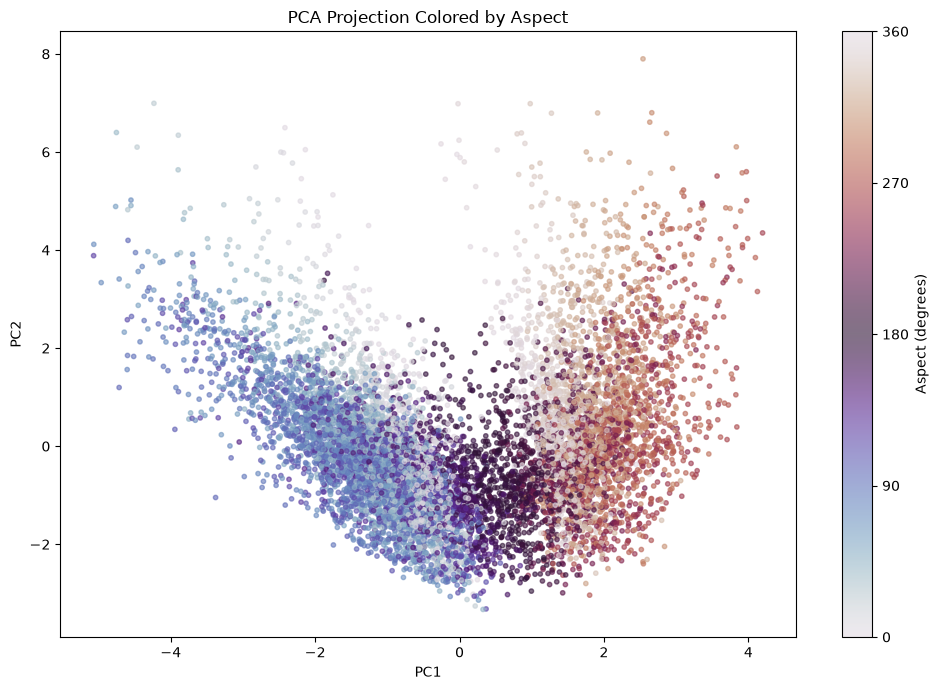

In [26]:
fig, ax = plt.subplots(figsize=(10, 7))

scatter = ax.scatter(
    pc1[sample_idx],
    pc2[sample_idx],
    c=X_train["Aspect"].iloc[sample_idx],
    cmap="twilight",
    s=10,
    alpha=0.6,
    vmin=0,
    vmax=360
)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Aspect (degrees)")
cbar.set_ticks([0, 90, 180, 270, 360])

ax.set_title("PCA Projection Colored by Aspect")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")

plt.tight_layout()
plt.show()

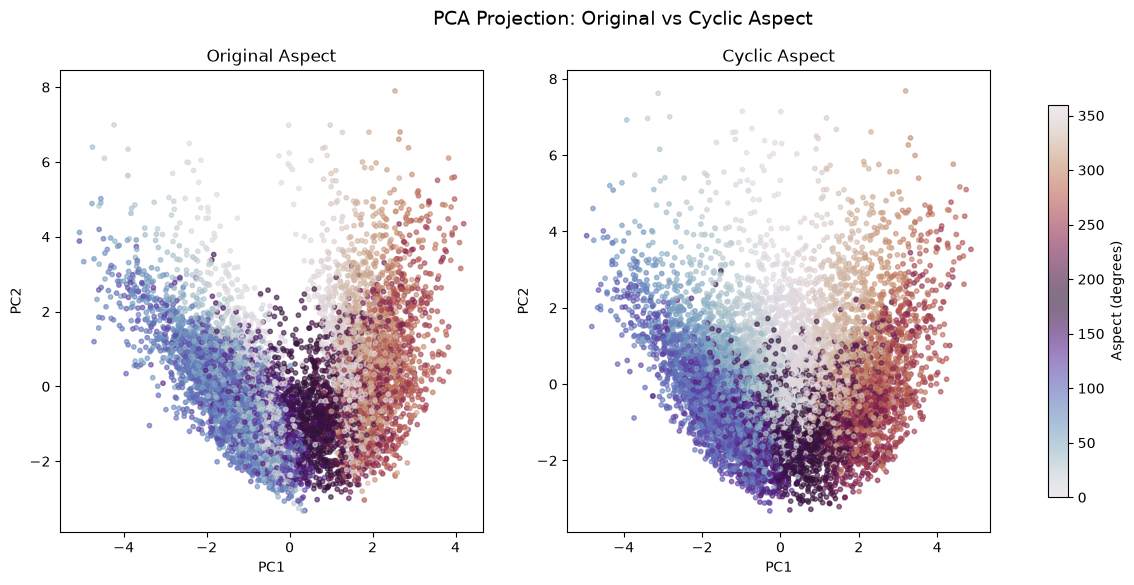

In [27]:
config_cyclic = PreprocessingConfig(
    pca="numeric",
    pca_components=11,
    cyclic_aspect=True,
)

preprocessor_cyclic = build_preprocessor(config_cyclic)

X_train_pca_cyclic = preprocessor_cyclic.fit_transform(X_train)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, data, title in zip(
    axes,
    [X_train_pca, X_train_pca_cyclic],
    ["Original Aspect", "Cyclic Aspect"]
):
    scatter = ax.scatter(
        data[sample_idx, 0],
        data[sample_idx, 1],
        c=X_train["Aspect"].iloc[sample_idx],
        cmap="twilight",
        s=10,
        alpha=0.6,
        vmin=0,
        vmax=360
    )

    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

fig.colorbar(
    scatter,
    ax=axes,
    label="Aspect (degrees)",
    shrink=0.85
)

plt.suptitle(
    "PCA Projection: Original vs Cyclic Aspect",
    fontsize=14
)

plt.show()

### PCA — Impact of Cyclic Aspect Encoding

Replacing the original `Aspect` variable with its sine and cosine components modifies the geometry of the PCA projection. The cyclic representation produces a somewhat different distribution, while the overall U-shaped structure remains visible.

This is expected, as the PCA axes are recomputed after the feature transformation and therefore represent different linear combinations of the input variables.

Although cyclic encoding provides a more appropriate geometric representation of angular data, the visual comparison does not establish an improvement in classification performance. This hypothesis will need to be evaluated experimentally using the classifiers.

### Global PCA — Explained Variance

We now investigate PCA applied to all 54 features, including the 10 numerical variables and the 44 one-hot encoded categorical indicators.

Unlike numerical PCA, global PCA can reduce the dimensionality of the entire feature space. However, standardizing rare binary variables gives them greater weight, potentially influencing the principal components.

We compare the number of components required to preserve 90%, 95% and 99% of the total standardized variance.

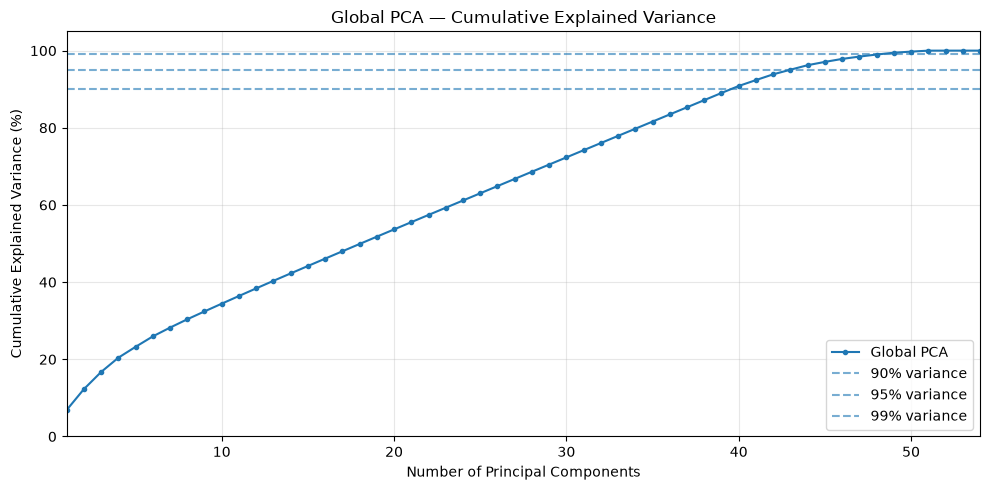

90% variance: 40 components
95% variance: 43 components
99% variance: 49 components


In [28]:
config_global = PreprocessingConfig(
    pca="all",
    pca_components=54,
    cyclic_aspect=False
)

preprocessor_global = build_preprocessor(config_global)
preprocessor_global.fit(X_train)

pca_global = (
    preprocessor_global
    .named_steps["features"]
    .named_steps["pca"]
)

global_variance = np.cumsum(
    pca_global.explained_variance_ratio_
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    np.arange(1, 55),
    global_variance * 100,
    marker=".",
    label="Global PCA"
)

for threshold in [90, 95, 99]:
    ax.axhline(
        threshold,
        linestyle="--",
        alpha=0.6,
        label=f"{threshold}% variance"
    )

ax.set_title("Global PCA — Cumulative Explained Variance")
ax.set_xlabel("Number of Principal Components")
ax.set_ylabel("Cumulative Explained Variance (%)")
ax.set_xlim(1, 54)
ax.set_ylim(0, 105)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

for threshold in [0.90, 0.95, 0.99]:
    n_components = np.searchsorted(
        global_variance, threshold
    ) + 1

    print(f"{threshold:.0%} variance: {n_components} components")

### Global PCA — Explained Variance Analysis

Global PCA was applied to all 54 standardized features, including numerical variables and one-hot encoded categorical indicators.

Unlike numerical PCA, the explained variance increases relatively gradually, without a pronounced elbow. Approximately 40, 44 and 49 principal components are required to preserve 90%, 95% and 99% of the total variance, respectively.

This behavior can partly be explained by the large number of binary features. Standardization assigns unit variance to each non-constant feature, including rare soil types, distributing the total variance across many dimensions.

Compared with numerical PCA, global PCA achieves a greater reduction in the total number of features, but also transforms the categorical indicators and reduces their direct interpretability.

Overall, neither approach provides an obvious advantage based on explained variance alone. Their usefulness will therefore be assessed through classification performance, particularly accuracy and macro F1-score.

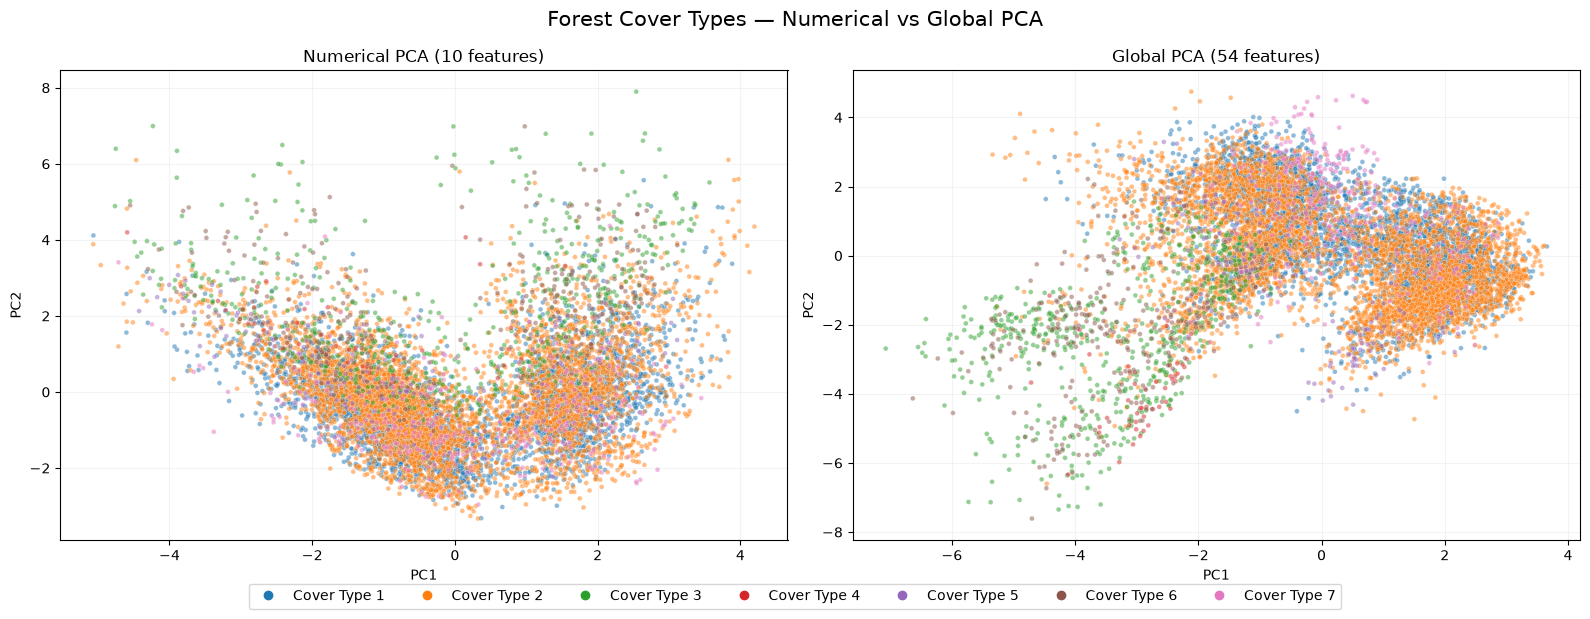

In [29]:
# Transform training data using both fitted preprocessors
X_numeric_pca = preprocessor.transform(X_train)
X_global_pca = preprocessor_global.transform(X_train)

# Use the same sample for both projections
labels = y_train.squeeze().iloc[sample_idx].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, data, title in zip(
    axes,
    [X_numeric_pca, X_global_pca],
    ["Numerical PCA (10 features)", "Global PCA (54 features)"]
):
    sns.scatterplot(
        x=data[sample_idx, 0],
        y=data[sample_idx, 1],
        hue=labels,
        palette="tab10",
        s=12,
        alpha=0.5,
        legend=False,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.grid(alpha=0.15)

# Common legend
handles = [
    plt.Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        color=sns.color_palette("tab10", 7)[i],
        label=f"Cover Type {i+1}"
    )
    for i in range(7)
]

fig.legend(
    handles=handles,
    loc="lower center",
    ncol=7,
    bbox_to_anchor=(0.5, -0.03)
)

plt.suptitle(
    "Forest Cover Types — Numerical vs Global PCA",
    fontsize=15
)

plt.tight_layout()
plt.show()

### Numerical vs. Global PCA — Class Separation

The projections onto the first two principal components reveal substantial differences between numerical and global PCA.

Numerical PCA produces a U-shaped distribution with considerable overlap between all seven forest cover classes. In contrast, global PCA reveals a more structured separation, particularly between cover types 3 and 6 and the predominantly represented types 1 and 2.

This difference may be explained by the inclusion of soil type and wilderness area indicators, which were previously found to be strongly associated with forest cover classes.

However, significant overlap remains, and improved visual separation in two dimensions does not necessarily imply better classification performance.

These observations motivate comparing both PCA approaches experimentally, alongside the original feature representation.

## A regarder dans un second temps pour optimiser

#### Is our data skewed ?

<span style="color: red;">blabla regarder ce qu'il faut ou ne faut pas avoir j'ai oublié</span>

In [ ]:
print('Skewness of the below features:')
print(X.skew())

Skewness of the below features:
Elevation                              -0.817596
Aspect                                  0.402628
Slope                                   0.789273
Horizontal_Distance_To_Hydrology        1.140437
Vertical_Distance_To_Hydrology          1.790250
Horizontal_Distance_To_Roadways         0.713679
Hillshade_9am                          -1.181147
Hillshade_Noon                         -1.063056
Hillshade_3pm                          -0.277053
Horizontal_Distance_To_Fire_Points      1.288644
Wilderness_Area1                        0.205618
Soil_Type1                             13.736670
Soil_Type2                              8.615358
Soil_Type3                             10.838630
Soil_Type4                              6.625176
Soil_Type5                             18.995243
Soil_Type6                              9.240061
Soil_Type7                             74.367173
Soil_Type8                             56.946415
Soil_Type9                           

Some data may be skewed, we might have to look into that later <span style="color: red;">(je me souviens pas de ce que veux dire le skew mais je crois que pour avoir de top resultats il faut corriger qqc. C'est plutot pour optimiser dans un second temps)</span> A voir plus tard oui 

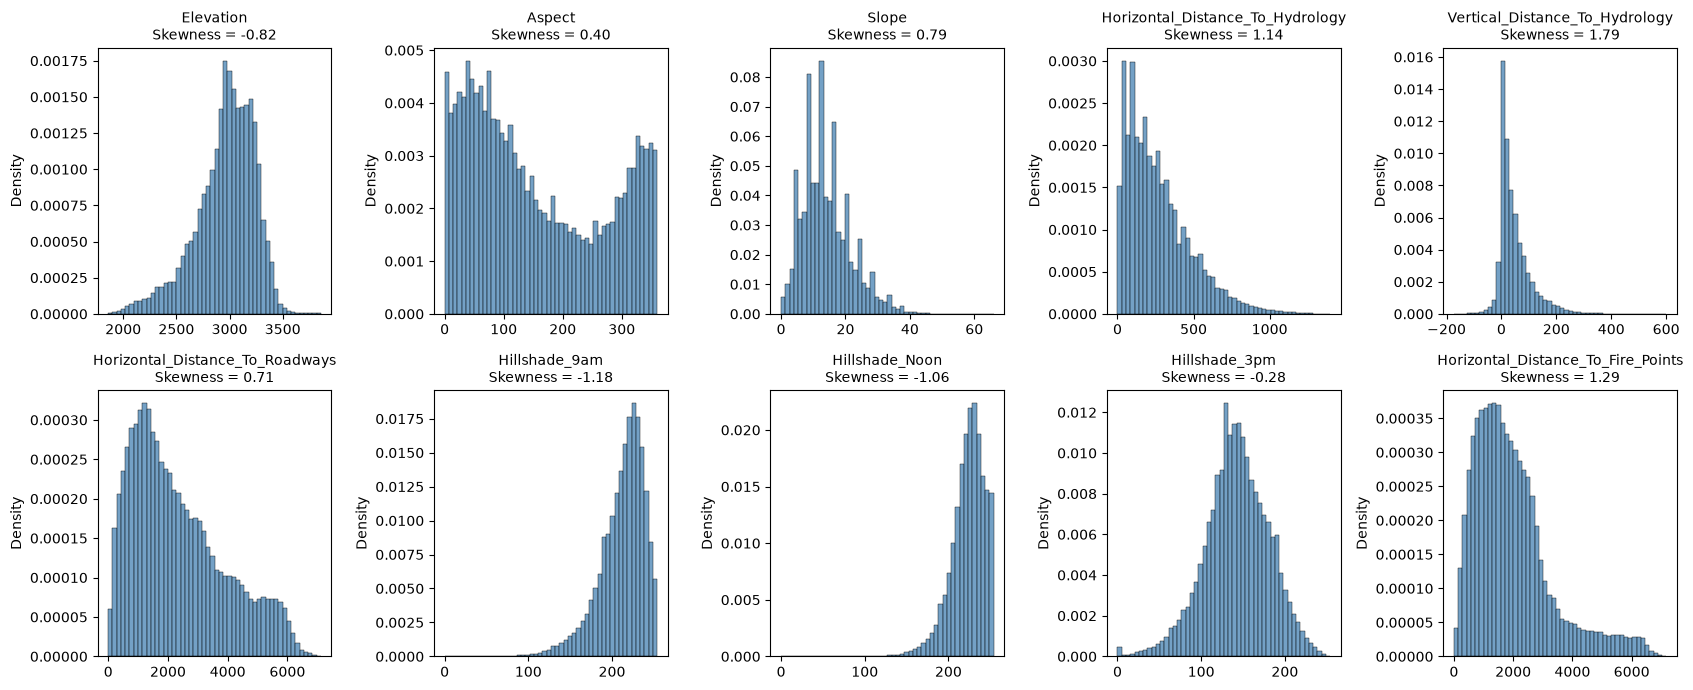

In [30]:
numeric_features = X.columns[:10]

fig, axes = plt.subplots(2, 5, figsize=(17, 7))
axes = axes.flatten()

for ax, feature in zip(axes, numeric_features):
    sns.histplot(
        X[feature],
        bins=50,
        stat="density",
        color="steelblue",
        ax=ax
    )

    skewness = X[feature].skew()

    ax.set_title(f"{feature}\nSkewness = {skewness:.2f}", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

### Feature Skewness Analysis

The numerical features exhibit varying degrees of asymmetry. Hydrological distances and distance to fire ignition points are positively skewed, with most observations concentrated at relatively low values and long tails extending toward larger distances.

Conversely, Hillshade_9am and Hillshade_Noon exhibit negative skewness, with observations concentrated toward the upper end of their bounded ranges. Elevation presents moderate negative skewness, while Hillshade_3pm is approximately symmetric.

Aspect is a special case due to its circular nature, making conventional skewness less meaningful. Its periodicity has already been addressed through optional sine/cosine encoding.

Importantly, skewness does not necessarily indicate a data quality problem or require correction. Tree-based models do not rely on normally distributed features, and other classifiers do not inherently require feature symmetry.

**We therefore retain the original numerical distributions**, while keeping standardization, cyclic Aspect encoding and PCA as configurable preprocessing options. Additional transformations may be investigated if subsequent classification results reveal a clear need.